In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape X_train: (60000, 28, 28)
Shape y_train: (60000,)
Shape X_test : (10000, 28, 28)
Shape y_test : (10000,)


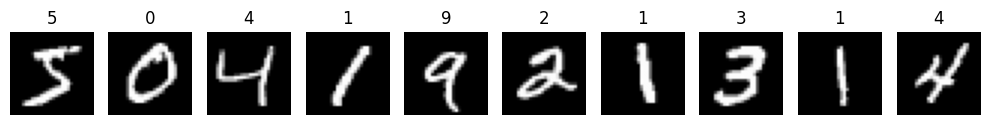

In [2]:
(X_train_raw, y_train_raw), (X_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

print("Shape X_train:", X_train_raw.shape)
print("Shape y_train:", y_train_raw.shape)
print("Shape X_test :", X_test_raw.shape)
print("Shape y_test :", y_test.shape)

# Visualisasi beberapa contoh digit MNIST
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train_raw[i], cmap='gray')
    plt.title(str(y_train_raw[i]))
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
# Flatten 28x28 -> 784 fitur dan normalisasi [0, 1]
X_train_flat = X_train_raw.reshape(-1, 28 * 28).astype('float32') / 255.0
X_test_flat = X_test_raw.reshape(-1, 28 * 28).astype('float32') / 255.0

print("Dimensi fitur setelah flatten:", X_train_flat.shape[1])

Dimensi fitur setelah flatten: 784


In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_flat, y_train_raw,
    test_size=0.2,
    random_state=42
)

print("Data Train:", X_train.shape, y_train.shape)
print("Data Val  :", X_val.shape, y_val.shape)
print("Data Test :", X_test_flat.shape, y_test.shape)

Data Train: (48000, 784) (48000,)
Data Val  : (12000, 784) (12000,)
Data Test : (10000, 784) (10000,)


In [5]:
input_dim = X_train.shape[1]  # 784

model_1 = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_1.summary()

history_1 = model_1.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9142 - loss: 0.2969 - val_accuracy: 0.9574 - val_loss: 0.1475
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9647 - loss: 0.1185 - val_accuracy: 0.9672 - val_loss: 0.1097
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9755 - loss: 0.0822 - val_accuracy: 0.9710 - val_loss: 0.0957
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9816 - loss: 0.0615 - val_accuracy: 0.9708 - val_loss: 0.0967
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9840 - loss: 0.0491 - val_accuracy: 0.9726 - val_loss: 0.0890
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9878 - loss: 0.0390 - val_accuracy: 0.9749 - val_loss: 0.0839
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9891 - loss: 0.0327 - val_accuracy: 0.9768 - val_loss: 0.0838
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9917 - loss: 0.0252 - val_accuracy: 0.

In [6]:
model_2 = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(256, activation='elu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='elu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='elu'),
    layers.Dense(10, activation='softmax')
])

model_2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_2.summary()

history_2 = model_2.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9004 - loss: 0.3279 - val_accuracy: 0.9463 - val_loss: 0.1766
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.9467 - loss: 0.1727 - val_accuracy: 0.9623 - val_loss: 0.1191
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9589 - loss: 0.1325 - val_accuracy: 0.9622 - val_loss: 0.1233
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9664 - loss: 0.1098 - val_accuracy: 0.9686 - val_loss: 0.1056
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9688 - loss: 0.0977 - val_accuracy: 0.9695 - val_loss: 0.1055
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9719 - loss: 0.0881 - val_accuracy: 0.9765 - val_loss: 0.0823
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9751 - loss: 0.0763 - val_accuracy: 0.9750 - val_loss: 0.0927
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9776 - loss: 0.0705 - val_accuracy

In [7]:
loss_1, acc_1 = model_1.evaluate(X_test_flat, y_test, verbose=0)
loss_2, acc_2 = model_2.evaluate(X_test_flat, y_test, verbose=0)

print(f"Akurasi Test Model 1 (ReLU [128, 64])          : {acc_1:.4f} (Loss: {loss_1:.4f})")
print(f"Akurasi Test Model 2 (ELU + Dropout [256,128,64]): {acc_2:.4f} (Loss: {loss_2:.4f})")

# Pilih model terbaik secara otomatis untuk laporan detail
best_model = model_2 if acc_2 >= acc_1 else model_1
best_name = "Model 2 (ELU + Dropout)" if acc_2 >= acc_1 else "Model 1 (ReLU)"
print(f"\nModel terbaik: {best_name}")

Akurasi Test Model 1 (ReLU [128, 64])          : 0.9677 (Loss: 0.1499)
Akurasi Test Model 2 (ELU + Dropout [256,128,64]): 0.9776 (Loss: 0.0871)

Model terbaik: Model 2 (ELU + Dropout)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
=== Classification Report ===
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.97      0.98      0.97       982
           5       0.97      0.97      0.97       892
           6       0.98      0.98      0.98       958
           7       0.96      0.99      0.97      1028
           8       0.98      0.96      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



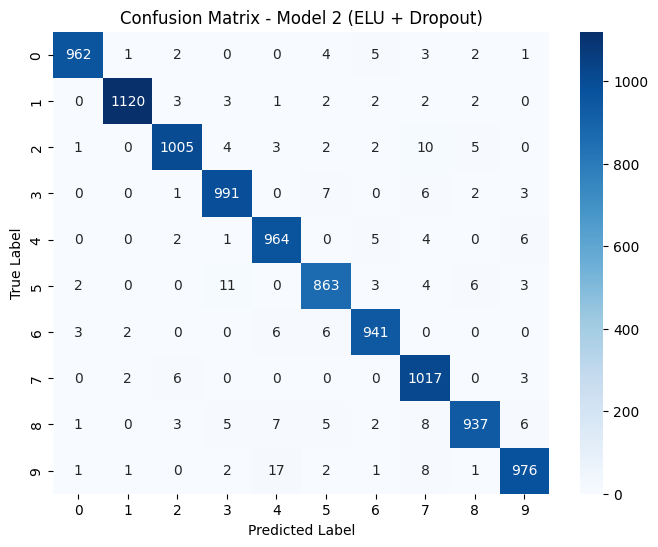

In [8]:
y_pred_prob = best_model.predict(X_test_flat)
y_pred = np.argmax(y_pred_prob, axis=1)

print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix - {best_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

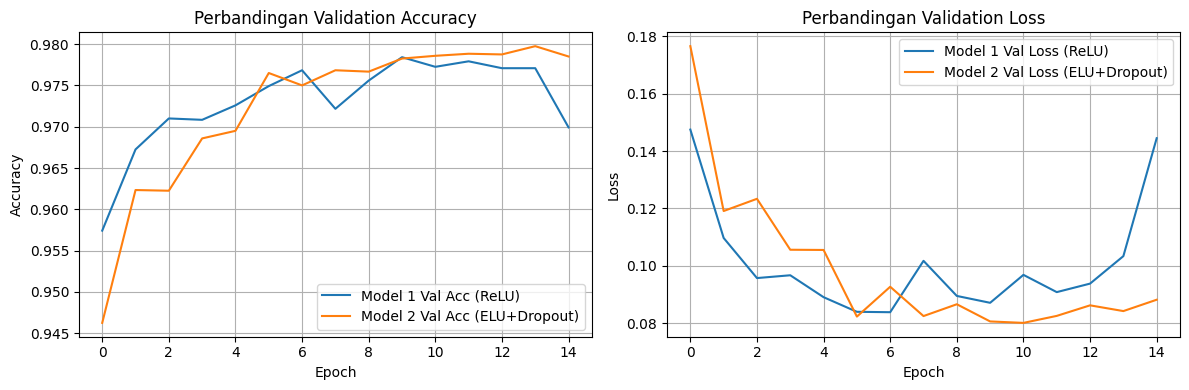

In [9]:
plt.figure(figsize=(12, 4))

# Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(history_1.history['val_accuracy'], label='Model 1 Val Acc (ReLU)')
plt.plot(history_2.history['val_accuracy'], label='Model 2 Val Acc (ELU+Dropout)')
plt.title('Perbandingan Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history_1.history['val_loss'], label='Model 1 Val Loss (ReLU)')
plt.plot(history_2.history['val_loss'], label='Model 2 Val Loss (ELU+Dropout)')
plt.title('Perbandingan Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
best_model.save('mnist_ann_model.h5')
print("Model berhasil disimpan sebagai mnist_ann_model.h5")

Model berhasil disimpan sebagai mnist_ann_model.h5
